# 19 · Phân tích đơn biến: nhãn, amount và độ phủ

**Câu hỏi:** phân phối nào ảnh hưởng đến xử lý dữ liệu? Đọc kết quả raw audit từ notebook 18; không dùng mẫu 1.000 khách. Biểu đồ lưu PNG và SVG trong `outputs/eda_insights_20261119/charts/`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
ROOT = Path.cwd()
if not (ROOT / 'data/MBD-mini').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data/MBD-mini').exists(), 'Mở notebook trong thư mục dự án'
AUDIT = ROOT / 'outputs/eda_insights_20261119'
TARGET = ROOT / 'outputs/target_focused_moscow_20261119'
FIG = ROOT / 'outputs/eda_insights_20261119/charts'
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans', 'figure.dpi':120,
    'axes.spines.top':False, 'axes.spines.right':False, 'axes.titlesize':13})
def save_chart(fig, name):
    fig.tight_layout()
    for ext in ('png','svg'):
        fig.savefig(FIG / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def read_audit(name):
    return pd.read_csv(AUDIT / name)


In [2]:
assert all(json.loads((AUDIT/'validation.json').read_text()).values())
labels=read_audit('label_monthly.csv')
labels['month']=pd.to_datetime(labels.month)
amount=read_audit('amount_by_currency.csv')
cards=read_audit('segment_cards.csv')
display(labels)
display(amount)

,month,n,buyers,rate
0,2022-02-01,100224,1041.0,0.010387
1,2022-03-01,100224,1567.0,0.015635
2,2022-04-01,100224,1698.0,0.016942
3,2022-05-01,100224,1100.0,0.010975
4,2022-06-01,100224,1177.0,0.011744
5,2022-07-01,100224,957.0,0.009549
6,2022-08-01,100224,1132.0,0.011295
7,2022-09-01,100224,1013.0,0.010107
8,2022-10-01,100224,868.0,0.008661
9,2022-11-01,100224,867.0,0.008651


,currency,n,missing_amount,zero_amount,negative_amount,minimum,median,p99,maximum
0,11.0,38724240,0,0,0,0.000003,1.802502e+04,5257532.0,1.370187e+12
1,3.0,20324,0,0,0,0.058873,8.939498e+04,115604080.0,1.141307e+10
2,15.0,16041,0,0,0,0.063511,4.059371e+05,271538620.0,1.527678e+10
3,4.0,3128,0,0,0,0.167505,1.238560e+04,112502520.0,1.716621e+09
4,17.0,446,0,0,0,4.509296,1.276568e+04,84856560.0,2.004374e+08
5,10.0,199,0,0,0,0.029000,1.437745e+04,50119756.0,2.402658e+08
6,8.0,174,0,0,0,11.315050,7.074836e+03,8311291.0,2.235006e+07
7,1.0,159,0,0,0,0.057873,1.153735e+04,18267822.0,2.028291e+07
8,NaN,118,0,0,0,148.637000,7.449037e+04,14062884.0,1.788642e+07
9,6.0,82,0,0,0,88.499560,5.038098e+05,394718940.0,5.703855e+08


## Nhãn qua đủ 12 tháng
Tỷ lệ dương dùng số khách–tháng có nhãn làm mẫu số. Biến động nền ảnh hưởng diễn giải lift và hiệu chỉnh xác suất.

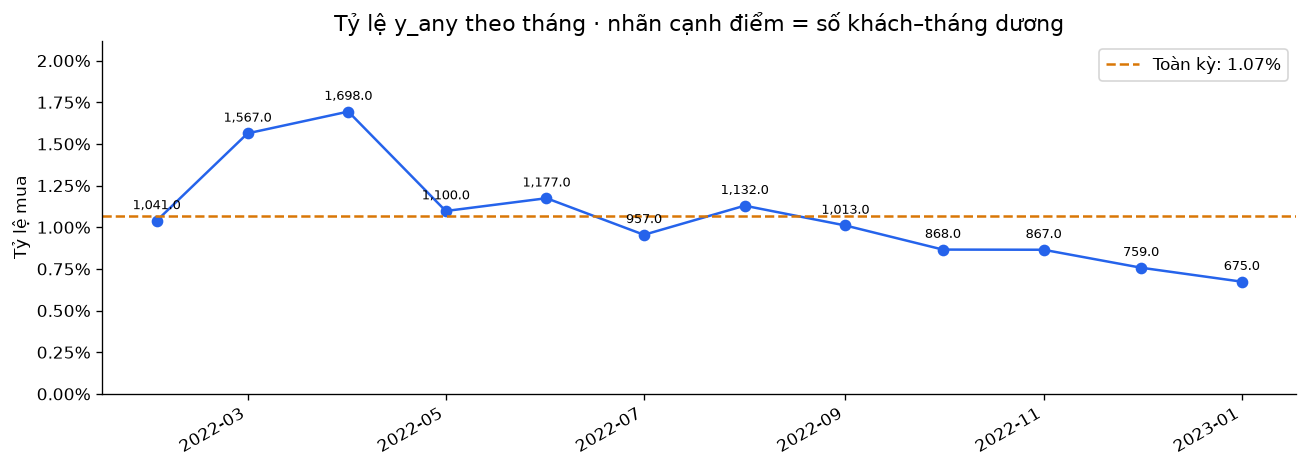

12,854.0/1,202,688 khách–tháng dương = 1.0688%


In [3]:
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(labels.month,labels.rate,marker='o',color='#2563eb')
pooled=labels.buyers.sum()/labels.n.sum()
ax.axhline(pooled,ls='--',color='#d97706',label=f'Toàn kỳ: {pooled:.2%}')
for r in labels.itertuples(): ax.annotate(f'{r.buyers:,}',(r.month,r.rate),xytext=(0,7),textcoords='offset points',ha='center',fontsize=8)
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0,labels.rate.max()*1.25)
ax.set_title('Tỷ lệ y_any theo tháng · nhãn cạnh điểm = số khách–tháng dương')
ax.set_ylabel('Tỷ lệ mua'); ax.legend(); fig.autofmt_xdate()
save_chart(fig,'19_target_monthly')
print(f'{labels.buyers.sum():,}/{labels.n.sum():,} khách–tháng dương = {pooled:.4%}')

## Amount theo currency
So median, p99 và max trên thang log. Đây là tóm tắt phân vị, không phải histogram raw. Giữ riêng mã tiền tệ; chưa có đơn vị đã xác minh để diễn giải thành doanh thu.

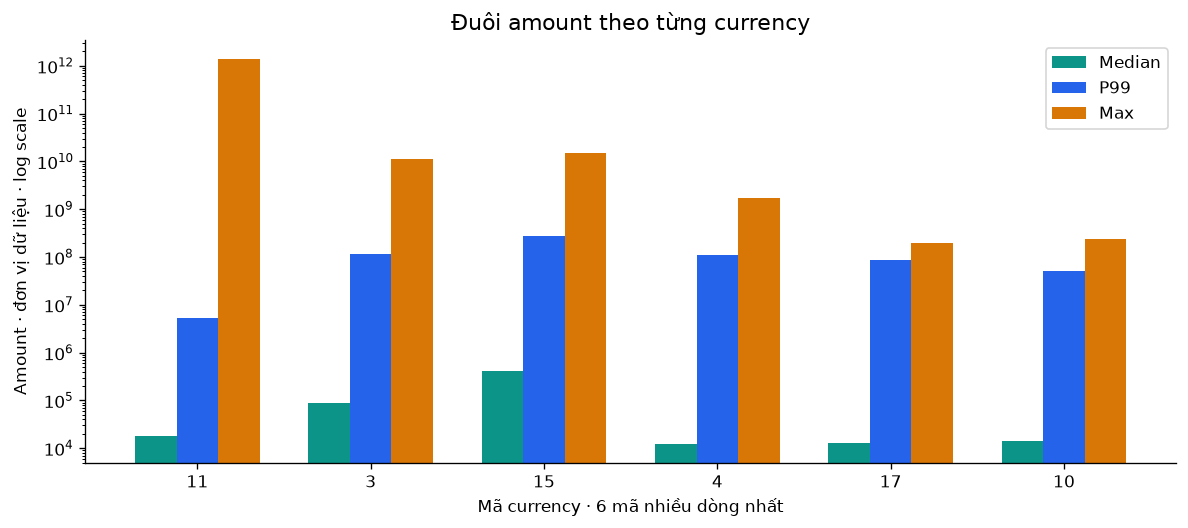

,currency,n,missing_amount,zero_amount,negative_amount,minimum,median,p99,maximum
0,11.0,38724240,0,0,0,0.000003,1.802502e+04,5257532.0,1.370187e+12
1,3.0,20324,0,0,0,0.058873,8.939498e+04,115604080.0,1.141307e+10
2,15.0,16041,0,0,0,0.063511,4.059371e+05,271538620.0,1.527678e+10
3,4.0,3128,0,0,0,0.167505,1.238560e+04,112502520.0,1.716621e+09
4,17.0,446,0,0,0,4.509296,1.276568e+04,84856560.0,2.004374e+08
5,10.0,199,0,0,0,0.029000,1.437745e+04,50119756.0,2.402658e+08
6,8.0,174,0,0,0,11.315050,7.074836e+03,8311291.0,2.235006e+07
7,1.0,159,0,0,0,0.057873,1.153735e+04,18267822.0,2.028291e+07
8,NaN,118,0,0,0,148.637000,7.449037e+04,14062884.0,1.788642e+07
9,6.0,82,0,0,0,88.499560,5.038098e+05,394718940.0,5.703855e+08


In [4]:
a=amount.head(6).copy()
names=a.currency.map(lambda x: 'missing' if pd.isna(x) else str(int(x)))
fig,ax=plt.subplots(figsize=(10,4.5)); x=np.arange(len(a))
for shift,col,label,color in [(-.24,'median','Median','#0d9488'),(0,'p99','P99','#2563eb'),(.24,'maximum','Max','#d97706')]:
    ax.bar(x+shift,a[col],width=.24,label=label,color=color)
ax.set_yscale('log'); ax.set_xticks(x,names); ax.set_xlabel('Mã currency · 6 mã nhiều dòng nhất')
ax.set_ylabel('Amount · đơn vị dữ liệu · log scale'); ax.set_title('Đuôi amount theo từng currency'); ax.legend()
save_chart(fig,'19_amount_quantiles')
display(amount[['currency','n','missing_amount','zero_amount','negative_amount','minimum','median','p99','maximum']])

**Diễn giải:** max rất xa median nên trung bình đơn lẻ dễ bị chi phối. Không tự xem điểm cực trị là lỗi. Ngưỡng biến đổi/cap nếu dùng cho mô hình phải được học từ phần train.

## Quy mô phân khúc feature
Count là tổng toàn bộ log trước cutoff. Mỗi khách có thể xuất hiện ở nhiều cutoff; không diễn giải tổng này là số khách duy nhất.

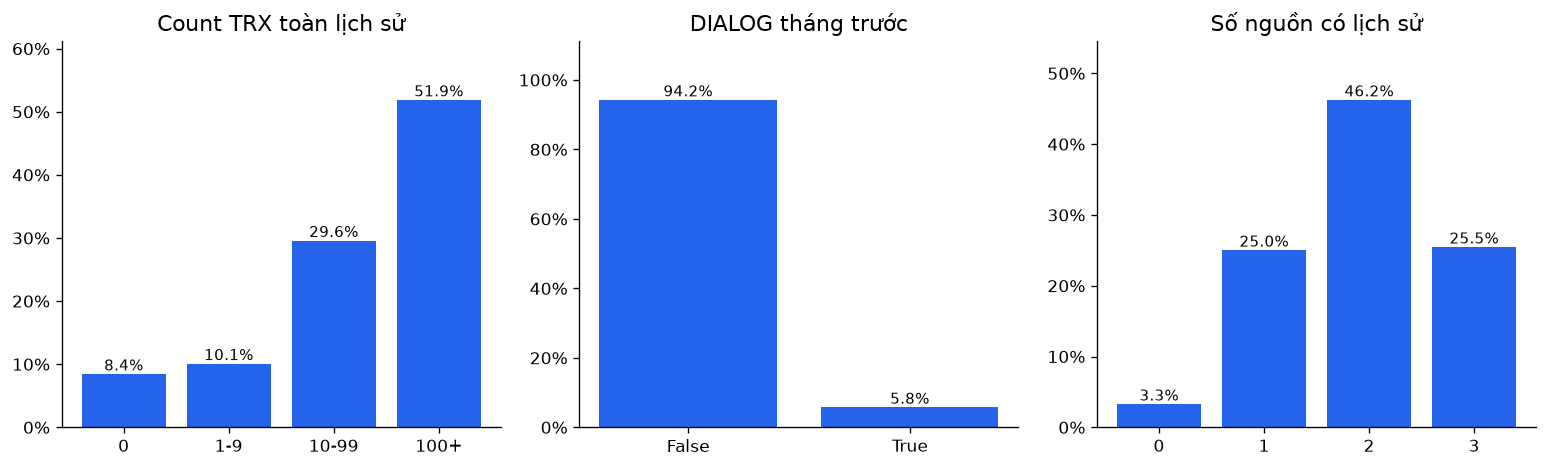

In [5]:
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,feature,title in zip(axes,['trx_band','dialog_recent','source_count'],['Count TRX toàn lịch sử','DIALOG tháng trước','Số nguồn có lịch sử']):
    a=cards[(cards.feature==feature)&(cards.horizon==1)]
    ax.bar(a.group.astype(str),a.population_share,color='#2563eb')
    ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_title(title)
    ax.set_ylim(0,a.population_share.max()*1.18)
    for i,v in enumerate(a.population_share): ax.text(i,v,f'{v:.1%}',ha='center',va='bottom',fontsize=9)
save_chart(fig,'19_segment_sizes')

## Checklist đơn biến
- [x] Nhãn theo 12 tháng; amount theo currency; quy mô nhóm count và masks.
- [ ] Refresh missing/cardinality/mức hiếm cho toàn bộ feature.
- [ ] Recency theo ngày, gap xuyên tháng, history age và active days.
- [ ] So độ nhạy kết luận khi xử lý ngoại lai.

Biểu đồ phân vị không thay thế histogram, và count phân nhóm không thay thế phân phối raw từng khách.